# TP : prédire le cours du CAC 40 avec des réseaux récurrents

## 1.0 Les cours

Cours de clôture quotidiens du CAC 40, en points, de janvier 2005 à novembre 2026. On entraîne sur les jours jusqu'à
fin 2017 et on valide sur les suivants : pas de tirage aléatoire, un modèle ne doit jamais s'entraîner sur un jour
postérieur à ceux sur lesquels on le juge.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
keras.utils.set_random_seed(0)

close = pd.read_csv("../cac40.csv", index_col="date", parse_dates=True)["close"]
CUT = "2018-01-01"
train_close, val_close = close[close.index < CUT], close[close.index >= CUT]

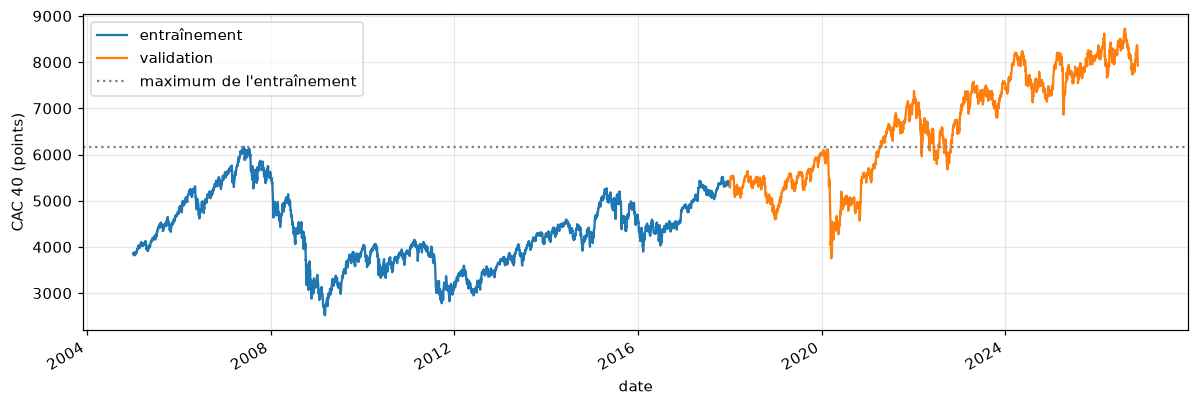

In [2]:
fig, ax = plt.subplots(figsize=(11, 3.8))
train_close.plot(ax=ax, label="entraînement")
val_close.plot(ax=ax, label="validation")
ax.axhline(train_close.max(), color="gray", linestyle=":", label="maximum de l'entraînement")
ax.set_ylabel("CAC 40 (points)")
ax.legend()
plt.tight_layout()
plt.show()

**Q1.** Un prévisionniste paresseux répond chaque jour : « demain, le CAC 40 clôturera où il a clôturé
aujourd'hui ». Quelle erreur typique attendez-vous de lui, comparée au niveau de l'indice ? Pourquoi sera-t-il
difficile à battre ?

**Réponse attendue :** Une erreur petite devant le niveau : l'indice bouge d'un jour à l'autre de quelques
dizaines de points sur plusieurs milliers, de l'ordre du pourcent. Il est difficile à battre parce que presque toute
la valeur de demain est déjà dans celle d'aujourd'hui : un modèle ne peut gagner que sur la petite variation qui
reste, et elle est bruitée.

## 1.1 Des fenêtres de cours

Le modèle lit les $W$ derniers cours de clôture et prédit le suivant. Une fenêtre a la forme $(W, 1)$ : $W$ jours, une
valeur par jour. Les cours sont ensuite ramenés entre 0 et 1 avec le minimum et le maximum de l'entraînement.

In [3]:
def make_windows(series, window):
    """All pairs (`window` consecutive values, the value right after them) of one series."""
    values = series.to_numpy()
    n = len(values) - window
    x = np.stack([values[i : i + window] for i in range(n)])
    return x[..., None].astype("float32"), values[window:].astype("float32")


x, y = make_windows(close, 20)
assert x.shape == (len(close) - 20, 20, 1) and y.shape == (len(close) - 20,)
assert np.allclose(x[0, :, 0], close.iloc[:20]) and np.isclose(y[0], close.iloc[20])

In [4]:
WINDOW = 20
X_train, y_train = make_windows(train_close, WINDOW)
X_val, y_val = make_windows(val_close, WINDOW)
print(f"entraînement : {X_train.shape}, validation : {X_val.shape}")

entraînement : (3302, 20, 1), validation : (2256, 20, 1)


In [5]:
lo, hi = train_close.min(), train_close.max()


def scale(values):
    """Min-max scaling of prices with the training minimum and maximum."""
    return ((values - lo) / (hi - lo)).astype("float32")


assert np.allclose(scale(np.array([lo, hi])), [0, 1])
Xs_train, ys_train, Xs_val, ys_val = scale(X_train), scale(y_train), scale(X_val), scale(y_val)

## 1.2 La référence « demain = aujourd'hui »

C'est la prévision à battre : elle ne sait rien de l'avenir et n'apprend rien.

In [6]:
mae_persistence_train = np.abs(y_train - X_train[:, -1, 0]).mean()
mae_persistence_val = np.abs(y_val - X_val[:, -1, 0]).mean()
assert np.isclose(mae_persistence_val, mean_absolute_error(y_val, X_val[:, -1, 0]))
print(f"« demain = aujourd'hui » : {mae_persistence_train:.0f} points en entraînement, {mae_persistence_val:.0f} en validation")

« demain = aujourd'hui » : 40 points en entraînement, 50 en validation


## 1.3 Un RNN simple

Une couche `SimpleRNN(32)` lit la fenêtre jour après jour. À chaque jour elle met à jour son état
$h_t = \tanh(x_t W_x + h_{t-1} W_h + b)$, avec $h_0 = 0$, et l'état $h_W$ du dernier jour passe dans une
couche `Dense(1)` qui sort le cours prévu.

**Q2.** Combien de paramètres compte la couche `SimpleRNN(32)` pour une valeur par jour ? Ce nombre change-t-il avec la
longueur $W$ de la fenêtre ?

**Réponse attendue :** $W_x$ est $1 \times 32$ (une valeur par jour, 32 unités), $W_h$ est $32 \times 32$ (chaque
unité lit les 32 états précédents) et $b$ a 32 termes : $32 + 1024 + 32 = 1088$. La couche `Dense(1)` ajoute
$32 + 1 = 33$ paramètres. Ce nombre ne dépend pas de $W$ : les mêmes poids servent à chaque jour, la fenêtre
ne fait que rallonger la boucle.

In [7]:
def build_model(cell, units, window):
    """A recurrent layer reading `window` days (one value per day), then one output: the next value."""
    return keras.Sequential([layers.Input(shape=(window, 1)), cell(units), layers.Dense(1)])


rnn = build_model(layers.SimpleRNN, 32, WINDOW)
rnn_params = 32 * 1 + 32 * 32 + 32
assert rnn_params == rnn.layers[0].count_params()
print(f"couche SimpleRNN : {rnn_params} paramètres, modèle entier : {rnn.count_params()}")

couche SimpleRNN : 1088 paramètres, modèle entier : 1121


## 1.4 La récurrence à la main

La couche calcule la formule ci-dessus, rien de plus. Refaites-la sur une fenêtre avec les poids de la couche.

In [8]:
W_x, W_h, b = rnn.layers[0].get_weights()  # shapes (1, 32), (32, 32) and (32,)

h = np.zeros(32)
for x_t in Xs_val[0]:  # the 20 days of one window, one at a time
    h = np.tanh(x_t @ W_x + h @ W_h + b)
assert np.allclose(h, keras.ops.convert_to_numpy(rnn.layers[0](Xs_val[:1]))[0], atol=1e-5)

## 1.5 Prévoir le cours avec le RNN simple

On entraîne le RNN sur les cours mis à l'échelle, puis on ramène ses prévisions en points.

RNN : 41 points en entraînement, 160 en validation


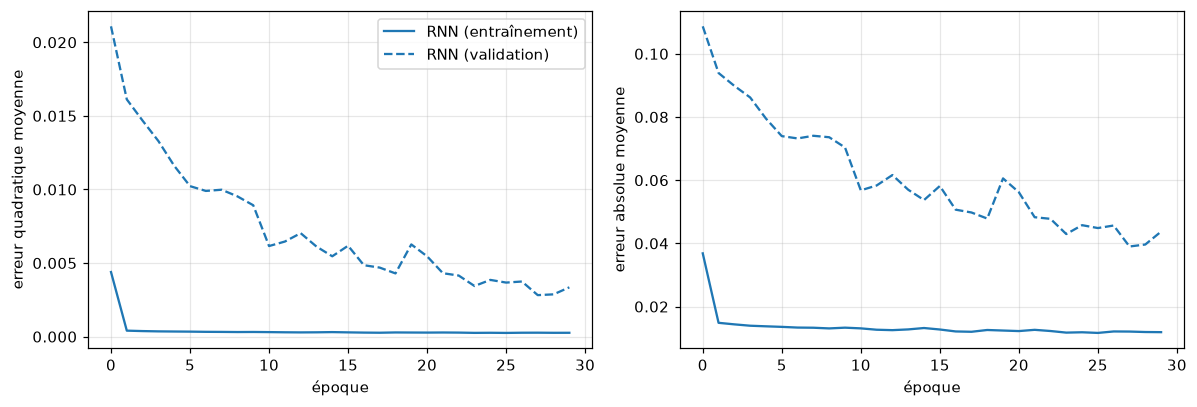

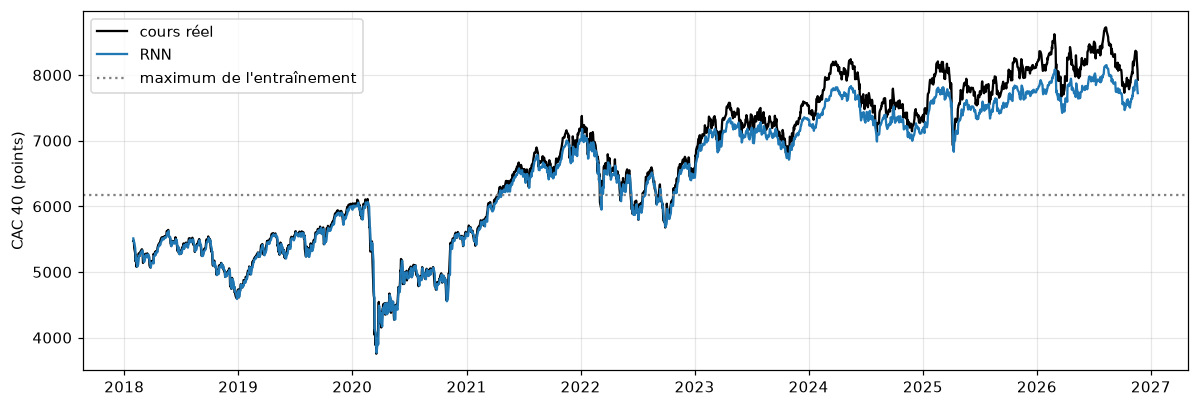

In [9]:
def train(model, X_train, y_train, X_val, y_val, epochs):
    """Trains on the training windows, validating after each epoch. Returns the cost and error of each epoch."""
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model.fit(X_train, y_train, epochs=epochs, batch_size=32,
                     validation_data=(X_val, y_val), verbose=0).history


def predict_points(model, Xs):
    """Forecast of the model for scaled windows, in index points."""
    return model.predict(Xs, verbose=0)[:, 0] * (hi - lo) + lo


def plot_curves(histories, reference=None):
    """Cost (MSE) and mean absolute error after each epoch, training (solid) and validation (dashed), one color per model."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for (name, history), color in zip(histories.items(), plt.cm.tab10.colors):
        for ax, metric in zip(axes, ["loss", "mae"]):
            ax.plot(history[metric], color=color, label=f"{name} (entraînement)")
            ax.plot(history[f"val_{metric}"], color=color, linestyle="--", label=f"{name} (validation)")
    for (name, mse), color in zip((reference or {}).items(), ["gray", "black"]):
        axes[0].axhline(mse, color=color, linestyle=":", label=name)
    for ax, label in zip(axes, ["erreur quadratique moyenne", "erreur absolue moyenne"]):
        ax.set_xlabel("époque")
        ax.set_ylabel(label)
    axes[0].legend()
    plt.tight_layout()
    plt.show()


def plot_forecasts(preds):
    """Closes of the validation period and the forecast of each model."""
    days = val_close.index[WINDOW:]
    plt.figure(figsize=(11, 3.8))
    plt.plot(days, y_val, color="black", label="cours réel")
    for (name, pred), color in zip(preds.items(), plt.cm.tab10.colors):
        plt.plot(days, pred, color=color, label=name)
    plt.axhline(train_close.max(), color="gray", linestyle=":", label="maximum de l'entraînement")
    plt.ylabel("CAC 40 (points)")
    plt.legend()
    plt.tight_layout()
    plt.show()


history_rnn = train(rnn, Xs_train, ys_train, Xs_val, ys_val, epochs=30)
assert len(history_rnn["val_loss"]) == 30
plot_curves({"RNN": history_rnn})
pred_rnn = predict_points(rnn, Xs_val)
assert pred_rnn.shape == y_val.shape
print(f"RNN : {mean_absolute_error(y_train, predict_points(rnn, Xs_train)):.0f} points en entraînement, "
      f"{mean_absolute_error(y_val, pred_rnn):.0f} en validation")
plot_forecasts({"RNN": pred_rnn})

**Q3.** Comparez l'erreur du RNN en entraînement et en validation à celle de « demain = aujourd'hui », et
regardez sur la figure où la prévision s'écarte du cours. Que s'est-il passé ?

**Réponse attendue :** En entraînement, l'erreur du RNN est proche de celle de « demain = aujourd'hui » ; en
validation, elle en est un multiple. Sur la figure, la prévision colle au cours tant qu'il reste sous le maximum de
l'entraînement (ligne pointillée), puis passe de plus en plus sous le cours réel. Mis à l'échelle de l'entraînement, un
cours au-dessus de ce maximum dépasse 1 : une valeur que le réseau n'a jamais vue et qu'il ne sait pas extrapoler, sa
sortie reste coincée dans la plage apprise. Au mieux il recopie le dernier cours, il ne le bat jamais.

## 1.6 LSTM et GRU

Même modèle, avec `layers.LSTM` puis `layers.GRU` à la place de `layers.SimpleRNN`, 32 unités chacun. Le LSTM
calcule quatre quantités par jour (portes d'oubli, d'entrée et de sortie, et candidat), le GRU trois (portes de mise
à jour et de réinitialisation, et candidat), le RNN simple une seule.

**Q4.** Sans exécuter : rangez les trois couches par nombre de paramètres, avec leurs rapports à celui du RNN
simple.

**Réponse attendue :** Dans l'ordre croissant : RNN simple, GRU, LSTM. Chaque quantité a la taille de celle du
RNN simple (1 088), donc le LSTM en compte quatre fois plus, 4 352. Le GRU en aurait trois fois plus, mais Keras
y ajoute un second vecteur de biais par quantité ($3 \times 32 = 96$ de plus), d'où 3 360.

RNN   1088 paramètres, 160 points en validation (« demain = aujourd'hui » : 50)
LSTM  4352 paramètres, 113 points en validation (« demain = aujourd'hui » : 50)
GRU   3360 paramètres, 108 points en validation (« demain = aujourd'hui » : 50)


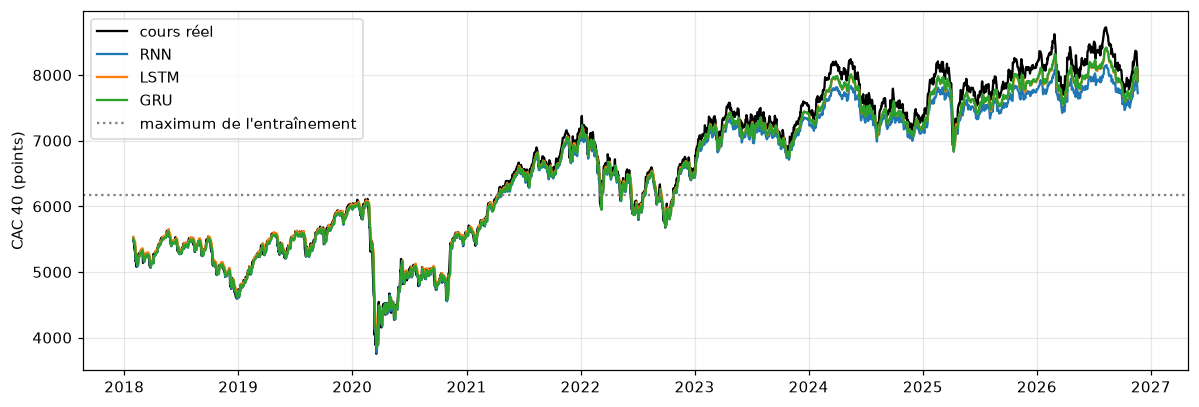

In [10]:
cells = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}
n_params, preds = {}, {}
for name, cell in cells.items():
    keras.utils.set_random_seed(0)
    model = build_model(cell, 32, WINDOW)
    n_params[name] = model.layers[0].count_params()
    train(model, Xs_train, ys_train, Xs_val, ys_val, epochs=30)
    preds[name] = predict_points(model, Xs_val)

assert set(preds) == set(cells) and n_params["RNN"] == rnn_params
plot_forecasts(preds)
for name in cells:
    print(f"{name:4s} {n_params[name]:5d} paramètres, {mean_absolute_error(y_val, preds[name]):.0f} points en validation "
          f"(« demain = aujourd'hui » : {mae_persistence_val:.0f})")

**Q5.** Les portes corrigent-elles ce que le RNN simple faisait mal ? Que conclure sur le choix de la cellule ?

**Réponse attendue :** En partie. Le LSTM et le GRU restent plus près du cours que le RNN simple au-delà du maximum de
l'entraînement, mais leur erreur reste bien supérieure à celle de « demain = aujourd'hui » : ils butent sur la même
plage. Le défaut vient de la cible, un niveau qui sort de ce qu'on a vu, pas de la cellule. En changer ne le répare
pas.

## 1.7 Prévoir la variation plutôt que le cours

Les cours futurs sortent de la plage vue à l'entraînement (figure de 1.0) ; la variation d'un jour, le **rendement**
$r_t = 100 \ln (P_t / P_{t-1})$ en pourcentage, reste dans la même plage d'une année à l'autre. Mêmes modèles, mêmes
fenêtres de 20 jours, mais sur les rendements : on prédit le rendement de demain, puis on en tire un cours.

**Q6.** Si les 20 derniers rendements permettaient de prévoir celui de demain, que ferait le marché ?

**Réponse attendue :** Des investisseurs achèteraient avant les hausses annoncées et vendraient avant les baisses,
ce qui ferait bouger le cours tout de suite, jusqu'à effacer la régularité. On s'attend donc à ce qu'aucun modèle ne
fasse mieux que « le rendement de demain est nul ».

In [11]:
returns = 100 * np.log(close).diff().dropna()
r_train, r_val = returns[returns.index < CUT], returns[returns.index >= CUT]
Xr_train, yr_train = make_windows(r_train, WINDOW)
Xr_val, yr_val = make_windows(r_val, WINDOW)
assert Xr_val.shape[0] == X_val.shape[0] and Xr_train.shape[0] == X_train.shape[0] - 1

mse_zero = np.mean(yr_val ** 2)
rate_up = np.mean(yr_val > 0)
assert np.isclose(mse_zero, mean_squared_error(yr_val, np.zeros_like(yr_val))) and 0.4 < rate_up < 0.6
print(f"rendement nul : erreur quadratique {mse_zero:.3f} ; « demain, hausse » : juste {rate_up:.1%} des jours")

rendement nul : erreur quadratique 1.312 ; « demain, hausse » : juste 52.9% des jours


RNN  erreur quadratique 1.392, sens juste 48.4%, cours : 52.1 points (« demain = aujourd'hui » : 49.7)
LSTM erreur quadratique 1.377, sens juste 48.4%, cours : 50.3 points (« demain = aujourd'hui » : 49.7)
GRU  erreur quadratique 1.386, sens juste 49.0%, cours : 50.4 points (« demain = aujourd'hui » : 49.7)


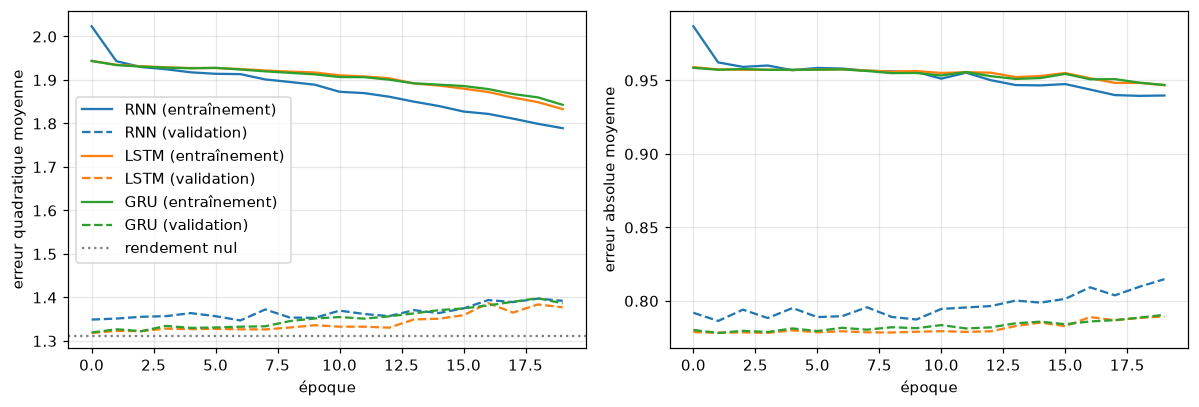

In [12]:
histories_r, preds_r = {}, {}
for name, cell in cells.items():
    keras.utils.set_random_seed(0)
    model = build_model(cell, 32, WINDOW)
    histories_r[name] = train(model, Xr_train, yr_train, Xr_val, yr_val, epochs=20)
    preds_r[name] = model.predict(Xr_val, verbose=0)[:, 0]

price_forecasts = {name: X_val[:, -1, 0] * np.exp(pred / 100) for name, pred in preds_r.items()}

plot_curves(histories_r, {"rendement nul": mse_zero})
for name, pred in preds_r.items():
    print(f"{name:4s} erreur quadratique {mean_squared_error(yr_val, pred):.3f}, sens juste {np.mean((pred > 0) == (yr_val > 0)):.1%}, "
          f"cours : {mean_absolute_error(y_val, price_forecasts[name]):.1f} points (« demain = aujourd'hui » : {mae_persistence_val:.1f})")

**Q7.** Lisez les courbes et le tableau. Un des modèles bat-il « rendement nul » ? Fait-il mieux que « demain,
hausse » sur le sens ? Que vaut son cours prévu face à « demain = aujourd'hui » ?

**Réponse attendue :** Non, sur les trois points. L'erreur quadratique de validation reste au-dessus de celle du rendement
nul, et elle monte au fil des époques pendant que celle d'entraînement baisse : les modèles apprennent le bruit de
l'entraînement, pas une régularité. Le sens est juste à peu près un jour sur deux, pas mieux que « demain, hausse ».
Et le cours prévu se trompe à peine moins ou plus que « demain = aujourd'hui » : le modèle prédit un rendement proche
de zéro, donc il recopie le dernier cours.

## 1.8 Ce que coûte l'erreur

Une règle de trading : on est acheteur le lendemain si le modèle prévoit une hausse, vendeur à découvert sinon. Le
gain du jour est la position (+1 ou −1) fois le rendement. Chaque unité de position achetée ou vendue coûte 0,05 % du montant : passer d'acheteur à vendeur en vaut deux.

**Q8.** Un modèle juste sur le sens 52 jours sur 100 est-il rentable avec cette règle ? Que faut-il calculer pour le
savoir ?

**Réponse attendue :** Pas nécessairement. Le gain dépend de l'amplitude des jours où il a raison ou tort, pas
seulement de leur nombre : quelques grosses baisses mal anticipées effacent beaucoup de petits gains. Et chaque
changement de position coûte des frais, d'autant plus qu'un modèle qui hésite change souvent. Il faut calculer le
rendement cumulé de la règle, brut puis net de frais.

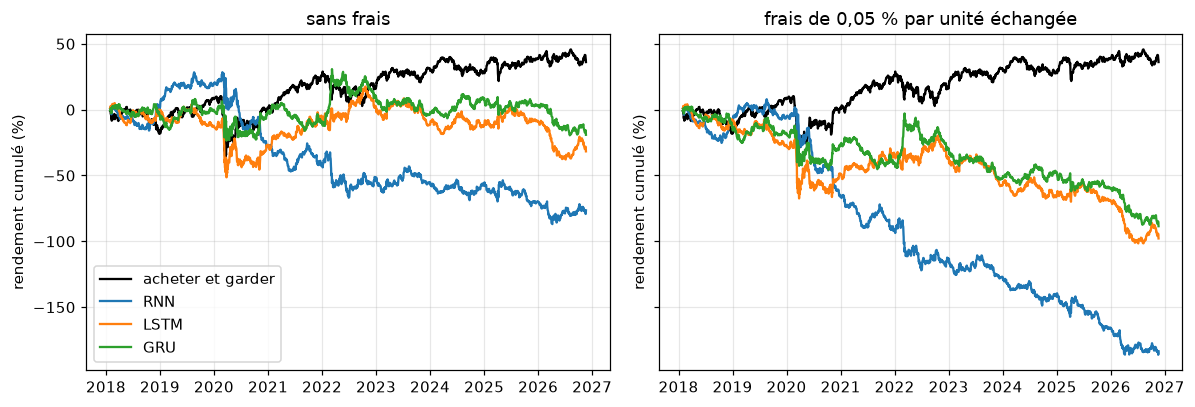

In [13]:
def strategy_returns(pred, y, cost=0.05):
    """Daily returns (%) of the rule "long if the forecast is positive, short otherwise", paying `cost` % per unit of position change."""
    position = np.where(pred > 0, 1.0, -1.0)
    change = np.abs(np.diff(position, prepend=0.0))
    return position * y - cost * change


assert np.isclose(strategy_returns(np.ones(len(yr_val)), yr_val, cost=0).sum(), yr_val.sum())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, cost, title in zip(axes, [0, 0.05], ["sans frais", "frais de 0,05 % par unité échangée"]):
    ax.plot(r_val.index[WINDOW:], np.cumsum(yr_val), color="black", label="acheter et garder")
    for (name, pred), color in zip(preds_r.items(), plt.cm.tab10.colors):
        ax.plot(r_val.index[WINDOW:], np.cumsum(strategy_returns(pred, yr_val, cost)), color=color, label=name)
    ax.set_title(title)
    ax.set_ylabel("rendement cumulé (%)")
axes[0].legend()
plt.tight_layout()
plt.show()

**Q9.** Lisez la figure. Utiliseriez-vous un de ces modèles pour acheter et vendre le CAC 40 ? Que conclure sur
la prévision du cours par un réseau récurrent ?

**Réponse attendue :** Non. Net de frais, les trois perdent de l'argent alors que l'indice, acheté et gardé, en gagne. Sans
frais, la courbe d'un modèle ne fait que refléter le hasard des jours où il a eu raison ou tort, et les frais, payés à
chaque changement de position, creusent l'écart parce que ces modèles changent souvent d'avis. Le cours d'un indice à
un jour ne se prévoit pas à partir de son seul passé : ce que ce passé annonçait serait déjà dans le cours (Q6). Le RNN
simple, le LSTM et le GRU font la même chose, recopier le dernier cours en y ajoutant un petit bruit : ce qui manque
est l'information, pas l'architecture, et une architecture plus riche ne la crée pas.